# **Pricing a run of tickets over a sixty-day selling window**
## **Integrative Project — Project B**

---

**Authors:** Alan Jesús Hernández Soto · Francisco Uriel Ledezma Chávez · Esteban Vega Campos · Santiago Villegas Baltazar
**Programme:** Ingeniería Financiera
**Institution:** ITESO — Universidad Jesuita de Guadalajara
**Course:** Comportamiento en las Finanzas y Toma de Decisiones
**Professor:** Luis Felipe Gómez Estrada
**Date:** 24 November 2026

---

This is additional work. Project A is the team's submission for the brief, and this
project was built afterwards, on the same framework and to the same evidential standard,
because the team wanted the revenue-management problem as well.

## Contents

0. [The project in plain terms](#s0)
1. [Step 1: the narrative](#s1)
2. [Step 2: core elements](#s2)
3. [Step 3: the mathematical model](#s3)
4. [Step 4: the uncertainty model](#s4)
5. [Step 5: designing policies](#s5)
6. [Step 6: evaluating policies](#s6)
7. [Results](#s7)
8. [Sensitivity to the reference-price effect](#s8)
9. [Recommendation, limitations and what we would do with more time](#s9)

<a id="s0"></a>

## 0. The project in plain terms

A promoter has two thousand seats and sixty days to sell them, and a seat unsold on the
day of the event is worth nothing. The price can move once a day within a fixed grid, and
the buyers are not indifferent to how it moves, because they remember what the ticket used
to cost and resent paying more than that.

The question is what to charge each day. The answer has to beat the best single fixed
price, because a promoter who cannot beat one number has no reason to accept the trouble
and the explaining that a moving price costs.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys, pathlib, warnings

HERE = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "src" / "dtp").is_dir())
os.chdir(HERE)
sys.path.insert(0, str(HERE / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dtp import config, policies, simulator

pd.set_option("display.width", 130)

# Every table below is produced by run_analysis.py, which tunes on one seed, evaluates on
# another and writes what it found to results/. This report reads those files rather than
# repeating the work, so the evaluation has one implementation and not two that can drift
# apart. `python run_analysis.py` regenerates all of them.
RESULTS = pathlib.Path("results")
summary = (RESULTS / "summary.txt").read_text(encoding="utf-8")
assert "SMOKE RUN" not in summary, "results/ holds a smoke run; run run_analysis.py first"

policies_table = pd.read_csv(RESULTS / "policies.csv")
paired_table = pd.read_csv(RESULTS / "paired_differences.csv")
sensitivity_table = pd.read_csv(RESULTS / "sensitivity_eta.csv")
fixed_table = pd.read_csv(RESULTS / "tuning_fixed.csv")
schedule_table = pd.read_csv(RESULTS / "tuning_schedule.csv")
lookahead_table = pd.read_csv(RESULTS / "tuning_lookahead.csv")
print(summary.split("\n")[0])

tuning on 200 scenarios from seed 20261120, reporting on 500 from seed 20261124


<a id="s1"></a>

## 1. Step 1: the narrative

Tickets go on sale sixty days before the event. Each morning the promoter sets one price,
from a grid running from forty to two hundred in steps of ten, and that price stands for
the day. Buyers arrive through the day, more of them as the date approaches, and each
decides alone whether the ticket is worth what it costs today.

What makes the decision sequential rather than a single choice of price is that every day
changes the next. A day of heavy selling leaves fewer seats and less time to sell the
rest, and a day at a high price moves the number buyers carry in their heads, so the same
price feels different depending on what came before it.

<a id="s2"></a>

## 2. Step 2: core elements

**Metrics.** Total revenue over the window, the probability of selling out, and the spread
of revenue across scenarios, since a promoter with a fixed cost base cares about the bad
cases and not only the average.

**Decisions.** One price per day, from the grid.

**Sources of uncertainty.** How many buyers arrive on a given day, and what each of them
is willing to pay.

**Known at the outset.** The capacity, the length of the window, the grid, and the
parameters of the demand model.

**Arrives over time.** The arrivals and their willingness to pay, one day at a time.

**What carries over.** Seats remaining, the days left, and the reference price buyers
hold. The first two are the reason the problem has a deadline and the third is the reason
yesterday's price is still part of today's problem.

<a id="s3"></a>

## 3. Step 3: the mathematical model

**State.** $S_t = (R_t, d_t, r_t, H_t)$: seats remaining as a count, days left as a
count, the reference price in pesos, and recent daily sales in tickets.

**Decision.** $x_t = p_t$, the price charged on day $t$, from the grid. Everything in
$S_t$ is known when it is chosen, and the day's arrivals are not.

**Exogenous information.** $W_{t+1} = (N_{t+1}, V_{t+1})$, the number of buyers who
arrive during day $t$ and the willingness to pay each carries.

**Transition function.**

$$
\begin{aligned}
N_{t+1} &\sim \text{Poisson}\bigl(\lambda(u_t)\,\kappa^{\,\mathbb{1}\{R_t < 0.1C\}}\bigr),
 \qquad u_t = t/(T-1)\\
\text{buy}_i &= \mathbb{1}\Bigl\{V_i \ge p_t + \eta\,(p_t-r_t)^{+} - \gamma\,(r_t-p_t)^{+}\Bigr\}\\
S_{t+1} &= \min\Bigl(R_t,\ \textstyle\sum_i \text{buy}_i\Bigr)\\
R_{t+1} &= R_t - S_{t+1}, \qquad r_{t+1} = \theta\,r_t + (1-\theta)\,p_t
\end{aligned}
$$

**Objective.** $\max_{\pi}\ \mathbb{E}\bigl[\sum_t p_t\,S_{t+1}\bigr]$, the expected
revenue over the window, reported with the sell-out probability and the spread.

Every equation above is given in the brief. What the brief leaves open, and is therefore
ours, is the shape of the arrival rate and the reference price the market starts from.

<a id="s4"></a>

## 4. Step 4: the uncertainty model

Arrivals are Poisson with a rate that rises toward the event. The brief does not fix the
shape and asks for it to be estimated from the Kaggle flight-prices data, treating a route
with fixed capacity and a deadline as a stand-in market. We wrote the fitting script,
`calibrate.py`, which reads that file in chunks, keeps one route, turns the panel into
tickets sold per day to departure and fits

$$\lambda(u) = A\,e^{Bu}$$

by least squares on the log. **The fit was not run.** The file is 31 GB, and with Project A
the graded submission and four days to the deadline, the team chose not to spend the
download on a project that is already additional work. The parameters used below are
therefore ours, chosen so that expected arrivals over the window are about 1.4 times
capacity, and the report says so wherever a number depends on them. The script is in the
repository so the fit can be run later, and the sensitivity section shows which
conclusions would survive a different curve.

In [2]:
expected = sum(simulator.arrival_rate(t / (config.SELLING_DAYS - 1))
               for t in range(config.SELLING_DAYS))
print(f"venue          {config.CAPACITY:,} seats over {config.SELLING_DAYS} days")
print(f"price grid     {len(config.PRICE_GRID)} prices, {config.PRICE_MIN:.0f} to "
      f"{config.PRICE_MAX:.0f} in steps of {config.PRICE_STEP:.0f}")
print(f"arrival rate   {simulator.arrival_rate(0.0):.1f} a day at the start, "
      f"{simulator.arrival_rate(1.0):.1f} on the last day")
print(f"expected buyers {expected:,.0f}, which is {expected / config.CAPACITY:.2f} "
      f"times capacity")
print(f"willingness to pay   median {config.WTP_MEDIAN:.0f}, log sd {config.WTP_LOG_SD}")
print(f"reference price      starts at {config.REFERENCE_START:.0f}, "
      f"theta {config.THETA}, eta {config.ETA}, gamma {config.GAMMA}")

venue          2,000 seats over 60 days
price grid     17 prices, 40 to 200 in steps of 10
arrival rate   20.0 a day at the start, 89.6 on the last day
expected buyers 2,794, which is 1.40 times capacity
willingness to pay   median 95, log sd 0.55
reference price      starts at 120, theta 0.8, eta 0.6, gamma 0.25


<a id="s5"></a>

## 5. Step 5: designing policies

| Policy | Class | Tunable parameters |
|---|---|---|
| The best single fixed price | baseline | the price, chosen by simulation |
| A published schedule | PFA | opening price, how far it falls, how hard it reacts to sales |
| Re-plan every day | DLA | the horizon looked over |

The schedule is a PFA because it is a closed-form function of days elapsed and seats
remaining with no optimisation at decision time. The re-planning rule is a DLA because it
writes down an explicit model of the remaining days, optimises over it with a
mixed-integer programme, implements only today's price and throws the rest away, which is
the course's definition and its rolling-horizon picture exactly.

The lookahead model is approximate in three ways, and each is a tilde variable in the
course's notation rather than an oversight. The horizon is truncated. Demand is replaced
by its expectation, so the Poisson draw and the spread of willingness to pay both
disappear. And the reference price is held at today's value across the horizon, because
letting it follow the prices being chosen would make the sales term depend on the
decisions through a product and the model would stop being linear.

<a id="s6"></a>

## 6. Step 6: evaluating policies

Every policy is given the same list of scenario seeds, so the buyers who arrive are the
same until the policy's own prices change what those buyers do. Tuning uses one seed and
the reported numbers another. Comparisons against the baseline are paired.

In [3]:
best_price = float(fixed_table.loc[fixed_table.revenue.idxmax(), "price"])
print(f"best fixed price {best_price:.0f} of {len(config.PRICE_GRID)} tried, on "
      f"{config.N_TUNE} tuning scenarios from seed {config.TUNE_SEED}")
print(fixed_table.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

best fixed price 80 of 17 tried, on 200 tuning scenarios from seed 20261120
 price    revenue     sold  sold_out
 40.00  80,000.00 2,000.00      1.00
 50.00 100,000.00 2,000.00      1.00
 60.00 120,000.00 2,000.00      1.00
 70.00 139,792.80 1,997.04      0.92
 80.00 140,075.60 1,750.94      0.00
 90.00 136,322.55 1,514.69      0.00
100.00 129,726.50 1,297.27      0.00
110.00 121,569.25 1,105.17      0.00
120.00 112,506.60   937.55      0.00
130.00 102,824.80   790.96      0.00
140.00  93,232.30   665.95      0.00
150.00  84,084.00   560.56      0.00
160.00  75,442.40   471.51      0.00
170.00  67,313.20   395.96      0.00
180.00  59,971.50   333.18      0.00
190.00  53,481.20   281.48      0.00
200.00  47,671.00   238.35      0.00


In [4]:
best = schedule_table.loc[schedule_table.revenue.idxmax()]
start, slope, scarcity = float(best.start), float(best.slope), float(best.scarcity)
print(f"best schedule: start {start:.0f}, slope {slope:.1f}, scarcity {scarcity:.1f}, "
      f"of {len(schedule_table)} combinations")
print(schedule_table.sort_values("revenue", ascending=False).head(8)
      .to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

best schedule: start 120, slope 0.6, scarcity 0.4, of 60 combinations


 start  slope  scarcity    revenue     sold  sold_out
120.00   0.60      0.40 137,494.20 1,861.19      0.00
120.00   0.60      0.20 137,291.65 1,721.63      0.00
120.00   0.40      0.40 137,030.00 1,662.03      0.00
120.00   0.80      0.20 136,708.30 1,977.68      0.39
120.00   0.80      0.00 135,961.30 1,785.38      0.00
120.00   0.40      0.20 135,273.30 1,526.11      0.00
120.00   0.60      0.00 135,142.30 1,547.71      0.00
140.00   0.60      0.40 134,752.35 1,669.13      0.00


In [5]:
horizon = int(lookahead_table.loc[lookahead_table.revenue.idxmax(), "horizon"])
print(f"best horizon {horizon}, tuned on a quarter of the scenarios because each day "
      f"solves a programme")
print(lookahead_table.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

best horizon 20, tuned on a quarter of the scenarios because each day solves a programme
 horizon    revenue     sold  sold_out
       5 141,778.40 1,996.68      0.90
      10 141,880.20 1,996.68      0.92
      20 141,912.20 1,996.60      0.90


<a id="s7"></a>

## 7. Results

In [6]:
results = policies_table.rename(columns={
    "revenue_mean": "revenue", "ci_low": "CI low", "ci_high": "CI high",
    "revenue_std": "sd", "revenue_p5": "5th", "revenue_p95": "95th",
    "sold": "tickets sold", "sell_out_probability": "sells out",
    "average_price": "average price"})
print(f"{config.N_EVAL} scenarios from seed {config.EVAL_SEED}, the same for every policy")
print(results.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

500 scenarios from seed 20261124, the same for every policy
                                    policy    class    revenue     CI low    CI high       sd        5th       95th  tickets sold  sells out  average price
                         Fixed price of 80 baseline 139,894.72 139,613.99 140,175.45 3,202.76 134,156.00 144,884.00      1,748.68       0.00          80.00
Schedule, start 120 slope 0.6 scarcity 0.4      PFA 137,156.12 136,808.07 137,504.17 3,970.79 130,978.50 144,114.00      1,859.16       0.00          73.76
                    Lookahead over 20 days      DLA 141,912.12 141,696.83 142,127.41 2,456.19 137,812.50 146,251.00      1,996.12       0.87          71.09


In [7]:
print(f"paired against {results.policy.iloc[0]}")
print(paired_table.rename(columns={"mean_difference": "mean difference",
                                   "ci_low": "CI low", "ci_high": "CI high"})
      .to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

paired against Fixed price of 80
                                    policy  mean difference    CI low   CI high  wins  significant
Schedule, start 120 slope 0.6 scarcity 0.4        -2,738.60 -2,893.46 -2,583.74  0.07         True
                    Lookahead over 20 days         2,017.40  1,876.56  2,158.24  0.91         True


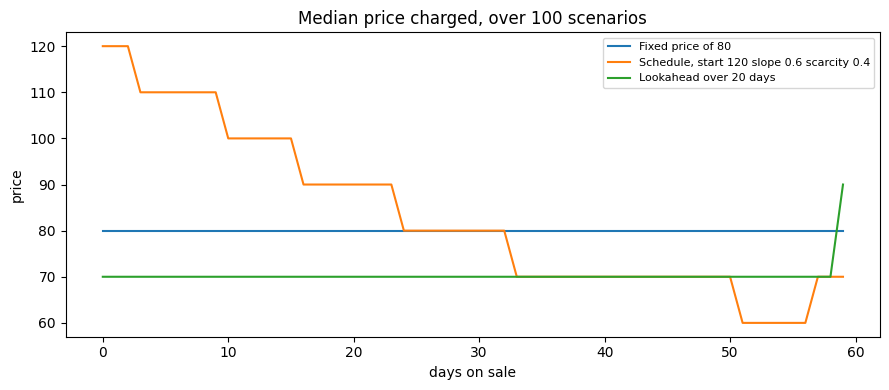

In [8]:
# The driver saves each policy's price path. How the seats went is already in the
# sell-out column above, so one panel is enough here.
price_paths = np.load(RESULTS / "price_paths.npy")
figure, axis = plt.subplots(figsize=(9, 4))
for paths, name in zip(price_paths, results.policy):
    axis.plot(np.arange(paths.shape[1]), np.median(paths, axis=0), label=name)
axis.set_xlabel("days on sale")
axis.set_ylabel("price")
axis.set_title(f"Median price charged, over {price_paths.shape[1]} scenarios")
axis.legend(fontsize=8)
plt.tight_layout()
plt.savefig("results/figures/paths.png", dpi=120)
plt.show()

<a id="s8"></a>

## 8. Sensitivity to the reference-price effect

The brief asks the dashboard to show how sensitive the results are to buyers comparing
today's price with the one they remember. The parameter is $\eta$, the penalty on a price
above the reference, and the table below re-runs every policy across a range of it on the
same scenarios.

It uses a subset of them. Four values of $\eta$ times three policies is twelve runs, and
the lookahead solves a mixed-integer programme for every day of every scenario, so at the
full sample this one table costs three times the comparison it is meant to test. A
sensitivity has to show the direction and the rough size of an effect rather than a
publishable interval, so it runs on the first 150 scenarios while the comparison above
keeps all 500. Every figure in this section is therefore noisier than the ones above it,
and none of them carries an interval for that reason.

One row of the table below is worth reading as a check on the mechanism rather than as a
result. The fixed price does not move with $\eta$ at all, and it should not: a price that
never changes drags the reference price onto itself, so $p_t - r_t$ goes to zero and the
penalty has nothing to act on. If that row ever moved, the reference-price update would be
wrong.

In [9]:
print(f"on {config.N_SENSITIVITY} of the {config.N_EVAL} scenarios, because the "
      f"lookahead solves a programme a day")
print()
print("revenue by resentment of a price above the remembered one")
print(sensitivity_table.pivot(index="policy", columns="eta", values="revenue")
      .to_string(float_format=lambda v: f"{v:,.0f}"))
print()
print("sell-out probability")
print(sensitivity_table.pivot(index="policy", columns="eta", values="sell_out_probability")
      .to_string(float_format=lambda v: f"{v:.3f}"))

on 150 of the 500 scenarios, because the lookahead solves a programme a day

revenue by resentment of a price above the remembered one
eta                                            0.0     0.3     0.6     1.0
policy                                                                    
Fixed price of 80                          139,837 139,837 139,837 139,837
Lookahead over 20 days                     142,577 142,257 141,889 141,431
Schedule, start 120 slope 0.6 scarcity 0.4 137,625 137,344 137,107 136,823

sell-out probability
eta                                          0.0   0.3   0.6   1.0
policy                                                            
Fixed price of 80                          0.000 0.000 0.000 0.000
Lookahead over 20 days                     0.867 0.867 0.820 0.747
Schedule, start 120 slope 0.6 scarcity 0.4 0.000 0.000 0.000 0.000


<a id="s9"></a>

## 9. Recommendation, limitations and what we would do with more time

### The recommendation

Read the two tables in section 7 together, in this order. The first says which policy earns
most and how wide the uncertainty around that figure is. The second says whether the gap
against a single fixed price is larger than the noise, which is the only comparison that
settles anything, because the policies meet the same buyers.

Recommend the re-planning rule **only if** its paired interval against the fixed price
excludes zero. If it does not, the honest advice to a promoter is the fixed price, because
a moving price costs something no table here measures: it has to be announced, it annoys
the buyers who went first, and it invites the question of whether tomorrow will be cheaper.
A policy that wins by less than its own error bar does not earn that trouble.

The second thing to tell the promoter is where the money actually comes from. The
re-planning rule does not win by being clever about any single day; it wins by selling the
last seats rather than leaving them unsold, which is visible in the sell-out column and in
the seats-remaining chart. A promoter who already sells out does not need it.

### Limitations

**The arrival curve was not calibrated.** This is the largest gap and it is ours rather
than the model's. The brief asks for the shape to be estimated from the Kaggle flight-prices
data, `calibrate.py` does exactly that, and it was not run, because the file is 31 GB and
Project A was the graded submission with four days left. Every level in this report
therefore rests on a curve we chose so that expected arrivals are about 1.4 times capacity.
What survives that choice is the **ranking** of policies under the sensitivity in section 8,
and what does not survive it is any statement about how much revenue a real promoter would
earn.

**Everything else about demand is assumed too.** The willingness-to-pay median and spread,
the memory parameter, the penalty for pricing above the reference and the reward for
pricing below it, and the scarcity multiplier are all numbers we set. The brief supplies
their functional form and not their values. Section 8 varies the one the brief singles out
and leaves the rest fixed, which is less than a full sensitivity analysis.

**Common random numbers are imperfect here, unlike in Project A.** Each scenario fixes a
seed, so two policies start from the same stream, but the number of arrivals is endogenous:
once a policy sells faster it crosses the scarcity threshold sooner and begins drawing a
different number of buyers. The scenarios are therefore shared at the start and drift apart
in a way a portfolio simulation does not. The paired intervals are still far tighter than
unpaired ones would be, and they are not the clean comparison the course's cash example
enjoys.

**The lookahead optimises a model it knows to be wrong.** It truncates the horizon, replaces
demand by its expectation and freezes the reference price across the horizon. The last of
these is the one worth naming to an examiner: letting the reference follow the prices being
chosen would make the sales term depend on the decisions through a product, and the model
would stop being a mixed-integer linear programme.

**No reinforcement-learning policy was implemented.** The brief asks for the baseline and at
least two of the other three, and we have the baseline, the schedule and the lookahead, so
the requirement is met. A DQN on this simulator is the obvious extension and the course's
own agent would be the starting point.

**One venue, one window, one buyer population.** Two thousand seats over sixty days with no
competing event, no resale market, no cancellations and no ability to add capacity. A
promoter facing any of those is facing a different problem.

### What we would do with more time

Run the calibration, in the order the script already implements, and report how far the
fitted curve sits from the one assumed here. Then re-run section 7 on the fitted curve and
say which of its conclusions moved. After that, train the reinforcement-learning agent,
because it is the only one of the four policy classes this project does not exercise and the
course spends three lectures on it.